# Diagnosing the current model

**The model under diagnosis** is the team's submission model (`demo_findings_and_model.ipynb`): a 50/50 rank blend of
- **logistic regression (LR):** 10 features, `C=0.1`, balanced class weights
- **LightGBM (GBM):** 14 features; 200 trees of depth 2, `scale_pos_weight=50`, averaged over seeds

It's trained on 2024 and validated on 2025 with the Phase 3 rules (top 0.69% = 243 rows, 52 positives).

**The evidence used:** training vs. validation scores, a confusion matrix and classification report at the operating point, learning curves, feature importance (three methods), subgroup performance, and the experiment log of everything tried so far.

**The questions:** bias vs. variance; overfitting; leakage; weak subgroups; redundant features; how reliable validation is; and diminishing returns. Then the three highest-value next experiments.

## 0. Setup: the team model, rebuilt with the shared feature code

In [1]:
import sys, warnings; warnings.filterwarnings("ignore")
from pathlib import Path
ROOT = next(p for p in [Path(".."), Path(".")] if (p / "ml" / "config.py").exists()).resolve()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, lightgbm as lgb
import matplotlib.pyplot as plt
from scipy.stats import rankdata, spearmanr
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, average_precision_score, confusion_matrix, classification_report
from sklearn.model_selection import StratifiedGroupKFold
from ml import config, data
from ml.featureset import FeatureBuilder
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 60)

BLUE, ORANGE, AQUA, INK, INK2, GRID, SURF = "#2a78d6", "#eb6834", "#1baf7a", "#0b0b0b", "#52514e", "#ecebe7", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF, "axes.edgecolor": "#d6d5d0",
                     "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlecolor": INK,
                     "axes.titlelocation": "left", "font.size": 10, "axes.grid": True, "grid.color": GRID,
                     "grid.linewidth": 0.8, "axes.axisbelow": True, "figure.dpi": 110, "legend.frameon": False})

con = data.connect()
train_rows, valid_rows = data.load_splits(con)
fb = FeatureBuilder(con)
tr, va = fb.transform(train_rows), fb.transform(valid_rows)
status = con.sql("SELECT cve_id, nvd_status FROM vulnerabilities").df()   # diagnostics only, never a model input
va = va.merge(status, on="cve_id", how="left"); tr = tr.merge(status, on="cve_id", how="left")

BASE = ["any_exploit", "poc_github", "nuclei", "log_assigner_kev_rate", "kw_unauth", "pr_none", "ui_none",
        "cvss_filled", "cwe_auth", "cwe_path"]
NEW4 = ["net_preauth", "log_batch_size", "log_cwe_kev_rate", "product_has_kev"]
GBM = dict(n_estimators=200, learning_rate=0.03, num_leaves=4, max_depth=2, min_child_samples=40, subsample=0.8,
           subsample_freq=1, colsample_bytree=0.8, reg_lambda=5, scale_pos_weight=50, verbose=-1)
def lr_model(): return make_pipeline(StandardScaler(), LogisticRegression(C=0.1, class_weight="balanced", max_iter=5000))
def fit_lr(A, B, cols=BASE): return lr_model().fit(A[cols], A.y).predict_proba(B[cols])[:, 1]
def fit_gbm(A, B, cols=BASE + NEW4, seeds=range(20)):
    return np.mean([lgb.LGBMClassifier(**GBM, random_state=s).fit(A[cols], A.y).predict_proba(B[cols])[:, 1] for s in seeds], axis=0)
blend = lambda a, b: 0.5 * rankdata(a) / len(a) + 0.5 * rankdata(b) / len(b)
K = lambda n: int(round(n * config.TOP_FRACTION))
def hits(y, s, k=None):
    y = np.asarray(y); k = k or K(len(y)); return int(y[np.argsort(-np.asarray(s, float), kind="stable")[:k]].sum())
def scores(y, s, k=None):
    return {"hits@k": hits(y, s, k), "AUC": round(roc_auc_score(y, s), 3), "AP": round(average_precision_score(y, s), 4)}
base = lambda d: (d.any_exploit * 10 + d.epss.fillna(0)).to_numpy()
print(f"train 2024: {len(tr):,} rows / {tr.y.sum()} positives (k={K(len(tr))}) | valid 2025: {len(va):,} / {va.y.sum()} (k={K(len(va))})")

train 2024: 28,839 rows / 33 positives (k=198) | valid 2025: 35,281 / 52 (k=243)


## 1. Training vs. validation scores

Each model is fitted on 2024 and scored on **its own training rows** (in-sample) and on 2025. A large training-minus-validation gap means **high variance** (overfitting). Low scores on *both* mean **high bias** (the model is too simple, or the features too weak).

In [2]:
p = {}
p["LR"] = (fit_lr(tr, tr), fit_lr(tr, va))
p["GBM"] = (fit_gbm(tr, tr), fit_gbm(tr, va))
p["Blend"] = (blend(*[p[m][0] for m in ["LR", "GBM"]]), blend(*[p[m][1] for m in ["LR", "GBM"]]))
p["Baseline: exploit then EPSS"] = (base(tr), base(va))
rows = []
for m, (s_tr, s_va) in p.items():
    a, b = scores(tr.y, s_tr), scores(va.y, s_va)
    rows.append({"model": m, "train hits (top 198 of 33)": a["hits@k"], "train AUC": a["AUC"], "train AP": a["AP"],
                 "valid hits (top 243 of 52)": b["hits@k"], "valid AUC": b["AUC"], "valid AP": b["AP"],
                 "AUC gap (train - valid)": round(a["AUC"] - b["AUC"], 3)})
fit_table = pd.DataFrame(rows).set_index("model"); fit_table

,train hits (top 198 of 33),train AUC,train AP,valid hits (top 243 of 52),valid AUC,valid AP,AUC gap (train - valid)
model,,,,,,,
LR,15,0.950,0.0727,17,0.869,0.1044,0.081
GBM,26,0.995,0.2213,18,0.905,0.1050,0.090
Blend,21,0.977,0.1604,19,0.897,0.1259,0.080
Baseline: exploit then EPSS,7,0.625,0.0263,14,0.768,0.0470,-0.143


**Reading this:**
- **Training recall is higher than validation recall:** logistic regression 45% (15 of 33) vs. 33% (17 of 52); LightGBM **79%** (26 of 33) vs. 35% (18 of 52); the blend 64% vs. 37%. LightGBM's training AUC is 0.995 against 0.905 on 2025.
- **The 2025 numbers are still good:** AUCs of 0.87-0.91, and 17-19 hits against the baseline's 14. So the model **overfits moderately** (LightGBM most), but it isn't collapsing on new data.
- *Seed sensitivity:* this run's blend scores 19, while the team notebook's scores 18. The only difference is how the 20 LightGBM seeds are drawn, so differences of about 1 hit are noise.

### Cross-validated view (the team's main test)

Repeated, grouped, stratified 5-fold cross-validation over 2024 + 2025 (85 positives, top 442). The spread across repeats shows how much the score moves from the luck of the split alone.

In [3]:
L = pd.concat([tr.assign(year=2024), va.assign(year=2025)], ignore_index=True).sort_values("cve_id").reset_index(drop=True)
yL = L.y.values; groups = (L.assigner.fillna("?") + "|" + L.published.astype(str)).values
R = 5; o_lr, o_gb = np.zeros((R, len(L))), np.zeros((R, len(L)))
for r in range(R):
    for f, (a, b) in enumerate(StratifiedGroupKFold(5, shuffle=True, random_state=r).split(L, yL, groups)):
        o_lr[r, b] = fit_lr(L.iloc[a], L.iloc[b]); o_gb[r, b] = fit_gbm(L.iloc[a], L.iloc[b], seeds=range(r * 100 + f * 3, r * 100 + f * 3 + 3))
cv_hits = {"LR": [hits(yL, o_lr[r]) for r in range(R)], "GBM": [hits(yL, o_gb[r]) for r in range(R)],
           "Blend": [hits(yL, blend(o_lr[r], o_gb[r])) for r in range(R)], "Baseline": [hits(yL, base(L))] * R}
pd.DataFrame({m: {"mean (top 442 of 85)": np.mean(v), "min": min(v), "max": max(v), "per repeat": v} for m, v in cv_hits.items()}).T

,mean (top 442 of 85),min,max,per repeat
LR,33.4,31,37,"[32, 31, 33, 34, 37]"
GBM,31.2,30,33,"[33, 32, 31, 30, 30]"
Blend,35.8,33,37,"[35, 33, 37, 37, 37]"
Baseline,22.0,22,22,"[22, 22, 22, 22, 22]"


**Reading this:** in cross-validation, the blend averages 35.8 of 85 in the top 442 (33-37 across repeats), against the baseline's 22. The blend beats either model alone (LR 33.4, LightGBM 31.2), so combining two different models helps.

## 2. Confusion matrix and classification report at the operating point

The model outputs a ranking, so "predicting positive" means **being in the top 243**: the list a team would patch, and the share the judges count.

In [4]:
s_va = p["Blend"][1]
flag = np.zeros(len(va), int); flag[np.argsort(-s_va, kind="stable")[:K(len(va))]] = 1
cm = confusion_matrix(va.y, flag)
print(pd.DataFrame(cm, index=["actual: not exploited", "actual: exploited"], columns=["not flagged", "flagged (top 243)"]))
print()
print(classification_report(va.y, flag, target_names=["not exploited", "exploited"], digits=3))
for budget in [0.0069, 0.02, 0.05, 0.10]:
    k = int(round(len(va) * budget)); f = np.zeros(len(va), int); f[np.argsort(-s_va, kind="stable")[:k]] = 1
    tp = int((f & va.y.values).sum())
    print(f"flag top {budget:.2%} ({k:,} rows): recall {tp / va.y.sum():.0%} ({tp} of {va.y.sum()}), precision {tp / k:.1%}, "
          f"lift {tp / k / va.y.mean():.0f}x")

                       not flagged  flagged (top 243)
actual: not exploited        35005                224
actual: exploited               33                 19

               precision    recall  f1-score   support

not exploited      0.999     0.994     0.996     35229
    exploited      0.078     0.365     0.129        52

     accuracy                          0.993     35281
    macro avg      0.539     0.680     0.563     35281
 weighted avg      0.998     0.993     0.995     35281

flag top 0.69% (243 rows): recall 37% (19 of 52), precision 7.8%, lift 53x
flag top 2.00% (706 rows): recall 46% (24 of 52), precision 3.4%, lift 23x
flag top 5.00% (1,764 rows): recall 58% (30 of 52), precision 1.7%, lift 12x
flag top 10.00% (3,528 rows): recall 65% (34 of 52), precision 1.0%, lift 7x


**Reading this:**
- **At the operating point** (flag the top 243): 19 true positives, 224 false alarms and 33 missed. Precision is 7.8% and recall 37%. That's a **53x lift** over the base rate: 1 in 13 flagged CVEs gets exploited, against 1 in 680 overall.
- **Accuracy (99.3%) and the "not exploited" row of the report are meaningless here.** Flagging nothing would score 99.85%.
- **Widening the list has diminishing returns:** the top 2% catches 46%, the top 5% 58% and the top 10% 65%. A fifth of the positives sit deep in the ranking, where no budget reaches them.

## 3. Learning curves: would more data help?

**Method:** train on a stratified random share of the 2024 rows (10% to 100%, 5 random draws each), and always validate on all of 2025. If validation keeps rising at 100%, more data should help (variance-limited). If it has flattened, the model or features are the limit (bias-limited).

**A time-respecting "more data" check:** validate on May-September 2025 only, and train either on 2024 alone, or on 2024 **plus** January-April 2025. That's more, and more recent, positives, without peeking at the test months.

In [5]:
fracs = [0.1, 0.2, 0.35, 0.5, 0.7, 1.0]
lc = []
pos_idx, neg_idx = np.flatnonzero(tr.y.values == 1), np.flatnonzero(tr.y.values == 0)
for f in fracs:
    for s in range(5 if f < 1 else 1):
        rng = np.random.default_rng(s)
        idx = np.sort(np.concatenate([rng.choice(pos_idx, max(2, int(round(f * len(pos_idx)))), replace=False),
                                      rng.choice(neg_idx, int(round(f * len(neg_idx))), replace=False)]))
        A = tr.iloc[idx]
        for m, fn in [("LR", lambda A, B: fit_lr(A, B)), ("GBM", lambda A, B: fit_gbm(A, B, seeds=range(3)))]:
            sv, st = fn(A, va), fn(A, A)
            lc.append({"fraction": f, "train positives": int(A.y.sum()), "model": m, "draw": s, "valid hits": hits(va.y, sv),
                       "valid AP": average_precision_score(va.y, sv), "valid AUC": roc_auc_score(va.y, sv),
                       "train AUC": roc_auc_score(A.y, st)})
lc = pd.DataFrame(lc)
curve = lc.groupby(["model", "fraction"]).agg(train_pos=("train positives", "mean"), valid_hits=("valid hits", "mean"),
                                              hits_min=("valid hits", "min"), hits_max=("valid hits", "max"),
                                              valid_AP=("valid AP", "mean"), valid_AUC=("valid AUC", "mean"),
                                              train_AUC=("train AUC", "mean")).round(3)
curve

train_pos  valid_hits  hits_min  hits_max  valid_AP  valid_AUC  train_AUC
model fraction                                                                           
GBM   0.10            3.0         7.4         3        13     0.032      0.813      1.000
      0.20            7.0        13.4         8        20     0.061      0.875      1.000
      0.35           12.0        13.0        11        16     0.069      0.871      0.999
      0.50           16.0        14.6        12        17     0.082      0.882      0.998
      0.70           23.0        17.0        14        19     0.106      0.895      0.997
      1.00           33.0        18.0        18        18     0.108      0.902      0.994
LR    0.10            3.0        10.4         0        18     0.046      0.779      0.991
      0.20            7.0        12.0         7        17     0.069      0.827      0.992
      0.35           12.0        12.4         9        15     0.057      0.788      0.948
      0.50           16.0        13.0         9        19     0.073      0.829      0.947
      0.70           23.0        17.0        15        20     0.094      0.859      0.947
      1.00           33.0        17.0        17        17     0.104      0.869      0.950

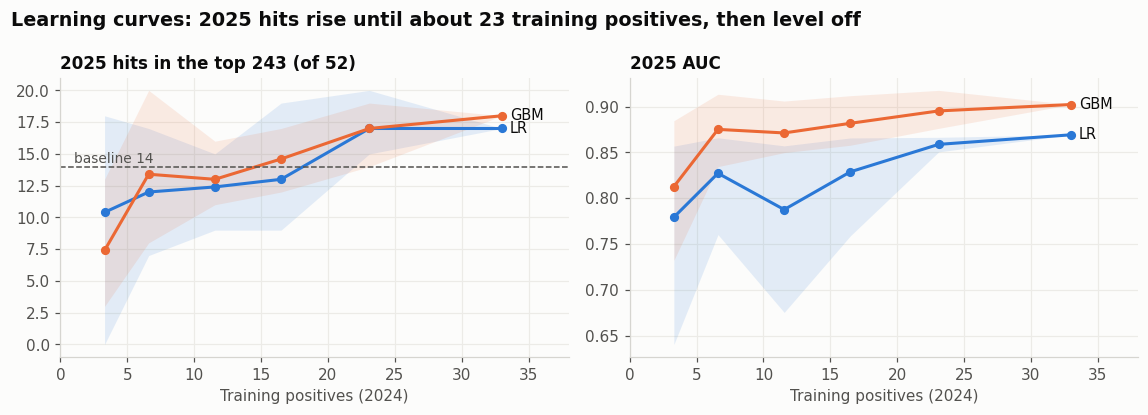

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.8))
for ax, metric, label in [(axes[0], "valid hits", "2025 hits in the top 243 (of 52)"), (axes[1], "valid AUC", "2025 AUC")]:
    for m, col in [("LR", BLUE), ("GBM", ORANGE)]:
        g = lc[lc.model == m].groupby("train positives" if False else "fraction")[metric]
        x = np.array(fracs) * tr.y.sum()
        ax.fill_between(x, g.min().values, g.max().values, color=col, alpha=0.12, linewidth=0)
        ax.plot(x, g.mean().values, color=col, lw=2, marker="o", ms=5)
        ax.text(x[-1] + 0.6, g.mean().values[-1], m, color=INK, va="center", fontsize=9.5)
    ax.set_xlabel("Training positives (2024)"); ax.set_title(label, fontsize=11); ax.set_xlim(0, tr.y.sum() + 5)
axes[0].axhline(hits(va.y, base(va)), color=INK2, lw=1, ls="--"); axes[0].text(1, hits(va.y, base(va)) + 0.3, "baseline 14", color=INK2, fontsize=9)
fig.suptitle("Learning curves: 2025 hits rise until about 23 training positives, then level off", x=0.01, ha="left", fontsize=12.5, fontweight="bold", color=INK)
plt.tight_layout(); plt.show()

In [7]:
late = va[va.snap >= "2025-05"]; early = va[va.snap <= "2025-04"]
more = pd.concat([tr, early])
rows = []
for name, A in [("train 2024 only", tr), ("train 2024 + Jan-Apr 2025", more)]:
    s_lr, s_gb = fit_lr(A, late), fit_gbm(A, late)
    rows.append({"training data": name, "train positives": int(A.y.sum()), "LR": hits(late.y, s_lr), "GBM": hits(late.y, s_gb),
                 "blend": hits(late.y, blend(s_lr, s_gb)), "blend AP": round(average_precision_score(late.y, blend(s_lr, s_gb)), 4)})
rows.append({"training data": "baseline (no training)", "blend": hits(late.y, base(late))})
print(f"test: May-Sep 2025, {len(late):,} rows, {late.y.sum()} positives, top {K(len(late))}")
pd.DataFrame(rows).set_index("training data").fillna("")

test: May-Sep 2025, 19,344 rows, 27 positives, top 133


,train positives,LR,GBM,blend,blend AP
training data,,,,,
train 2024 only,33.0,4.0,11.0,9,0.0779
train 2024 + Jan-Apr 2025,58.0,6.0,10.0,8,0.0606
baseline (no training),,,,8,


**Reading this:**
- **The learning curves rise steeply, then level off.** 2025 hits climb from about 7-10 (3 training positives) to 17 at 23 positives, then barely move at 33 (LightGBM 18, LR 17). Average precision follows the same shape (LightGBM 0.106 → 0.108 between 70% and 100%).
- **Training AUC is near 1.0 for LightGBM at every size:** it can always fit what it's given.
- **The time-respecting "more data" test doesn't help:** adding January-April 2025 (33 → 58 training positives) scores 8 against 9 on May-September 2025 (27 positives). On those late months, the model (9) **barely beats the baseline (8)**.
- **Taken together:** more of the same data is past its steep gain, and the model's edge is weaker in the most recent months. That points to **variance plus drift**, not plain lack of data.

## 4. Feature importance, three ways

1. **LR weights** (on standardized inputs): direction and size of each feature's effect, holding the others fixed.
2. **LightGBM gain:** how much each feature improved the trees' splits *in training*.
3. **Permutation importance on 2025:** shuffle one feature in the validation rows and measure how much the blend's **average precision** drops. This is the only one of the three measured on unseen data. AP is used instead of hits@243 because it moves smoothly, while hits jump in whole units.
4. **Drop-one ablation:** retrain without each feature, then compare 2025 hits and AP.

In [8]:
lr_fit = lr_model().fit(tr[BASE], tr.y)
w = pd.Series(lr_fit[-1].coef_[0], index=BASE)
gbms = [lgb.LGBMClassifier(**GBM, random_state=s).fit(tr[BASE + NEW4], tr.y) for s in range(20)]
gain = pd.Series(np.mean([m.booster_.feature_importance("gain") for m in gbms], axis=0), index=BASE + NEW4)
gain = gain / gain.sum()

def blend_fixed(B):
    a = lr_fit.predict_proba(B[BASE])[:, 1]; b = np.mean([m.predict_proba(B[BASE + NEW4])[:, 1] for m in gbms], axis=0)
    return blend(a, b)
ref_ap = average_precision_score(va.y, blend_fixed(va))
perm = {}
for c in BASE + NEW4:
    drops = []
    for s in range(10):
        B = va.copy(); B[c] = np.random.default_rng(s).permutation(B[c].values)
        drops.append(ref_ap - average_precision_score(va.y, blend_fixed(B)))
    perm[c] = np.mean(drops)

abl = {}
for c in BASE + NEW4:
    lr_cols = [x for x in BASE if x != c]; gb_cols = [x for x in BASE + NEW4 if x != c]
    s = blend(fit_lr(tr, va, lr_cols), fit_gbm(tr, va, gb_cols, seeds=range(10)))
    abl[c] = (hits(va.y, s), average_precision_score(va.y, s))
full = blend(fit_lr(tr, va), fit_gbm(tr, va, seeds=range(10)))
imp = pd.DataFrame({"LR weight": w, "GBM gain share": gain, "permutation AP drop (2025)": pd.Series(perm),
                    "hits without it (full: %d)" % hits(va.y, full): pd.Series({c: v[0] for c, v in abl.items()}),
                    "AP without it (full: %.4f)" % average_precision_score(va.y, full): pd.Series({c: v[1] for c, v in abl.items()})})
imp.sort_values("permutation AP drop (2025)", ascending=False).round(4)

,LR weight,GBM gain share,permutation AP drop (2025),hits without it (full: 19),AP without it (full: 0.1250)
log_assigner_kev_rate,1.6824,0.4381,0.0890,18,0.1043
cvss_filled,1.2191,0.2185,0.0648,24,0.1352
nuclei,0.1292,0.0038,0.0340,18,0.0940
poc_github,0.1919,0.0364,0.0222,18,0.1180
ui_none,-0.1025,0.0378,0.0198,16,0.1169
log_batch_size,NaN,0.1126,0.0169,20,0.1127
any_exploit,0.0531,0.0408,0.0131,17,0.1194
kw_unauth,0.5258,0.0206,0.0045,17,0.1304
cwe_auth,0.1304,0.0016,0.0017,18,0.1232
cwe_path,0.2373,0.0045,0.0015,19,0.1232


**Reading this:**
- **Assigner history dominates:** the largest LR weight (1.68), 44% of LightGBM's gain, and the biggest drop when shuffled on 2025.
- **CVSS score (`cvss_filled`) is a puzzle:** the *fitted* model uses it heavily (shuffling it costs AP 0.065), yet **retraining without it raises 2025 hits from 19 to 24 and AP from 0.125 to 0.135.** When it's removed, the other features take over its useful part, and what it alone adds appears not to carry over from 2024 to 2025. It's also a "Careful" column: who scores it (NIST or the vendor) differs between years.
- **Six features contribute about nothing on 2025:** `pr_none` (−0.001), `net_preauth` (−0.001), `log_cwe_kev_rate` (−0.004), `product_has_kev` (+0.001), `cwe_auth` (+0.002) and `cwe_path` (+0.002). Removing any of them moves hits by 0-3 and AP by under 0.003, which is within noise.
- **Caution:** a single drop-one run on 52 positives is noisy (detectable gain ≈ 6 hits; see §8), so the CVSS result is a **hypothesis to test**, not a conclusion.

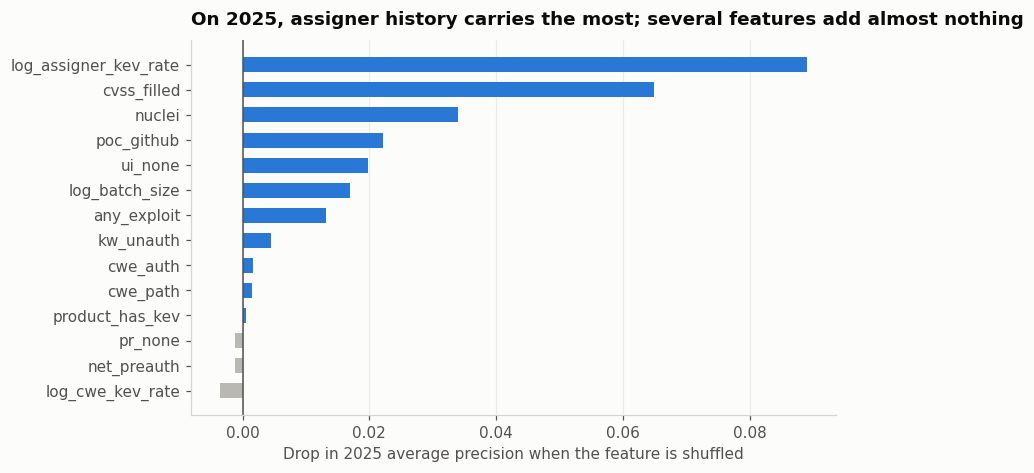

In [9]:
s_ = imp["permutation AP drop (2025)"].sort_values()
fig, ax = plt.subplots(figsize=(7.8, 4.4))
ax.barh(s_.index, s_.values, color=[BLUE if v > 0 else "#b9b8b2" for v in s_.values], height=0.6)
ax.axvline(0, color=INK2, lw=1); ax.grid(axis="y", visible=False)
ax.set_xlabel("Drop in 2025 average precision when the feature is shuffled")
ax.set_title("On 2025, assigner history carries the most; several features add almost nothing", pad=10)
plt.tight_layout(); plt.show()

## 5. Redundancy: which features say the same thing?

The Spearman correlation between every pair of model features in the training rows. Pairs above 0.7 carry largely overlapping information.

In [10]:
feats = BASE + NEW4
corr = tr[feats].corr(method="spearman")
pairs = [(a, b, corr.loc[a, b]) for i, a in enumerate(feats) for b in feats[i + 1:] if abs(corr.loc[a, b]) >= 0.5]
print(pd.DataFrame(pairs, columns=["feature A", "feature B", "Spearman"]).sort_values("Spearman", key=abs, ascending=False).round(3).to_string(index=False))
print(f"\npoc_github implies any_exploit in {((tr.poc_github == 1) & (tr.any_exploit == 1)).sum() / max(tr.poc_github.sum(), 1):.0%} of rows; "
      f"share of exploit-code rows that are GitHub PoC: {tr.poc_github.sum() / tr.any_exploit.sum():.0%}")
print(f"net_preauth = av_network x pr_none x ui_none (an exact function of features already present)")

  feature A   feature B  Spearman
any_exploit  poc_github     0.936
    pr_none net_preauth     0.605

poc_github implies any_exploit in 100% of rows; share of exploit-code rows that are GitHub PoC: 88%
net_preauth = av_network x pr_none x ui_none (an exact function of features already present)


**Reading this:**
- **`poc_github` nearly duplicates `any_exploit`** (Spearman 0.94): 88% of rows with exploit code have a GitHub proof of concept.
- **`net_preauth` is an exact product** of three other features, and correlates 0.61 with `pr_none`.
- Neither pair causes harm here (tree models and regularized LR tolerate it), but each duplicate adds a parameter to estimate from very few positives.

## 6. Which subgroups does the model miss?

For each group of 2025 rows: how many positives there are, how many the blend puts in its top 243, and how well it ranks *within* the group (AUC). Two columns, **NIST reviewed** and **CVSS blank**, are used **only to diagnose**, never as features.

In [11]:
THIRD_PARTY = {"cve@mitre.org", "disclosure@vulncheck.com", "security-advisories@github.com", "security@wordfence.com",
               "audit@patchstack.com", "cna@vuldb.com"}
v = va.assign(score=s_va, flagged=flag, rank=rankdata(-s_va, method="ordinal"))
v["month group"] = np.select([v.snap <= "2025-02", v.snap <= "2025-06"], ["Jan-Feb (EPSS gap)", "Mar-Jun"], "Jul-Sep")
v["exploit code at snapshot"] = np.where(v.any_exploit == 1, "yes", "no")
v["assigner kind"] = np.where(v.assigner.isin(THIRD_PARTY), "third-party CNA", "vendor / other")
v["NIST reviewed (diag.)"] = np.where(v.nvd_status.isin(["Analyzed", "Modified"]), "reviewed", "not reviewed")
v["CVSS blank (diag.)"] = np.where(v.cvss3_score.isna(), "blank", "scored")
v["old ID (2+ yrs)"] = np.where((pd.to_datetime(v.published).dt.year - v.cve_id.str[4:8].astype(int)) >= 2, "old ID", "current ID")
def sub(col):
    out = []
    for g, d in v.groupby(col):
        out.append({"group": f"{col}: {g}", "rows": len(d), "positives": int(d.y.sum()), "in top 243": int(d.flagged.sum()),
                    "hits": int((d.y & d.flagged).sum()), "recall": f"{(d.y & d.flagged).sum() / max(d.y.sum(), 1):.0%}",
                    "precision": f"{(d.y & d.flagged).sum() / max(d.flagged.sum(), 1):.1%}",
                    "within-group AUC": round(roc_auc_score(d.y, d.score), 2) if 0 < d.y.sum() < len(d) else np.nan})
    return out
subs = pd.DataFrame(sum([sub(c) for c in ["month group", "exploit code at snapshot", "assigner kind", "old ID (2+ yrs)",
                                           "NIST reviewed (diag.)", "CVSS blank (diag.)"]], [])).set_index("group")
subs

,rows,positives,in top 243,hits,recall,precision,within-group AUC
group,,,,,,,
month group: Jan-Feb (EPSS gap),7931,13,32,3,23%,9.4%,0.90
month group: Jul-Sep,11702,13,112,4,31%,3.6%,0.90
month group: Mar-Jun,15648,26,99,12,46%,12.1%,0.90
exploit code at snapshot: no,34520,30,154,4,13%,2.6%,0.85
exploit code at snapshot: yes,761,22,89,15,68%,16.9%,0.87
assigner kind: third-party CNA,18800,22,79,9,41%,11.4%,0.89
assigner kind: vendor / other,16481,30,164,10,33%,6.1%,0.90
old ID (2+ yrs): current ID,32549,51,224,19,37%,8.5%,0.90
old ID (2+ yrs): old ID,2732,1,19,0,0%,0.0%,0.88


In [12]:
missed = v[(v.y == 1)].sort_values("rank")
missed["KEV delay (days)"] = (pd.to_datetime(missed.kev_date) - pd.to_datetime(missed.published)).dt.days
print(f"Positives caught: {int(missed.flagged.sum())} of {len(missed)}. Rank of the missed ones: median {int(missed[missed.flagged == 0]['rank'].median()):,}")
print("Missed positives: exploit code at snapshot", f"{missed[missed.flagged == 0].any_exploit.mean():.0%}",
      "| caught positives:", f"{missed[missed.flagged == 1].any_exploit.mean():.0%}")
mi = missed[missed.flagged == 0]
print(f"Missed positives with EPSS percentile >= 0.9: {(mi.epss_pct >= 0.9).sum()} of {len(mi)} "
      f"({((mi.epss_pct >= 0.9) & (mi.any_exploit == 0)).sum()} without exploit code). All 2025 rows with EPSS >= 0.9 and no exploit code: "
      f"{((v.epss_pct >= 0.9) & (v.any_exploit == 0)).sum():,} rows, {int(v.y[(v.epss_pct >= 0.9) & (v.any_exploit == 0)].sum())} positives")
order_ = np.argsort(-s_va, kind="stable"); ex = v.any_exploit.values == 1; topm = v.flagged.values == 1
for name, seg in [("exploit code", ex), ("no exploit code", ~ex)]:
    so = order_[seg[order_]]; inside, outside = so[topm[so]], so[~topm[so]]
    print(f"{name}: {len(inside)} slots in the top 243 with {int(v.y.values[inside].sum())} hits; "
          f"last 50 inside -> {int(v.y.values[inside[-50:]].sum())} hits; next 50 outside -> {int(v.y.values[outside[:50]].sum())} hits")
missed[["cve_id", "rank", "flagged", "any_exploit", "epss_pct", "assigner kind", "log_assigner_kev_rate", "KEV delay (days)", "snap"]].round(3).head(52)

Positives caught: 19 of 52. Rank of the missed ones: median 4,249
Missed positives: exploit code at snapshot 21% | caught positives: 79%
Missed positives with EPSS percentile >= 0.9: 11 of 33 (7 without exploit code). All 2025 rows with EPSS >= 0.9 and no exploit code: 2,903 rows, 9 positives
exploit code: 89 slots in the top 243 with 15 hits; last 50 inside -> 8 hits; next 50 outside -> 2 hits
no exploit code: 154 slots in the top 243 with 4 hits; last 50 inside -> 1 hits; next 50 outside -> 0 hits


,cve_id,rank,flagged,any_exploit,epss_pct,assigner kind,log_assigner_kev_rate,KEV delay (days),snap
19966,CVE-2025-3248,1,1,1,1.000,third-party CNA,-3.748,28,2025-04
20621,CVE-2025-34028,2,1,1,0.995,third-party CNA,-3.748,10,2025-04
16815,CVE-2025-2776,4,1,1,0.994,third-party CNA,-3.385,76,2025-05
10640,CVE-2025-20281,10,1,1,0.877,vendor / other,-4.384,33,2025-06
14671,CVE-2025-24813,11,1,1,1.000,vendor / other,-3.996,22,2025-03
16808,CVE-2025-2775,18,1,1,0.992,third-party CNA,-3.385,76,2025-05
16550,CVE-2025-2746,26,1,0,0.915,third-party CNA,-3.707,210,2025-03
16558,CVE-2025-2747,27,1,0,0.915,third-party CNA,-3.707,210,2025-03
20493,CVE-2025-33073,29,1,1,0.959,vendor / other,-3.511,132,2025-06
6302,CVE-2024-53704,54,1,0,0.304,vendor / other,-3.122,40,2025-01


**Reading this: where the model fails.**
- **CVEs without exploit code at the snapshot are the main weakness.** They hold **30 of the 52 positives (58%)**, but the model catches only **4** of them (13% recall), against 15 of 22 (68%) for CVEs with exploit code. Within that group, ranking is still decent (AUC 0.85). The positives just don't rise far enough above 34,520 other rows. Of the 33 missed positives, only 7 had exploit code.
- **EPSS doesn't rescue them:** 11 missed positives have a top-10% EPSS, but the 2,903 rows with high EPSS and no exploit code contain only 9 positives (0.3%). EPSS alone is too weak a signal there.
- **Moving slots between groups barely helps:** the last 50 no-exploit rows inside the top 243 hold 1 hit, and the next 50 exploit-code rows just outside hold 2.
- **January-February 2025 is weakest** (23% recall). That's the period with the EPSS data gap and the older EPSS model.
- **Wasted slots:** 19 of the 243 slots (8%) go to **old-ID** CVEs (IDs reserved 2+ years before publication). That group has 1 positive in 2,732 rows, and none in the list.
- **Third-party CNAs** (MITRE, VulnCheck, GitHub...) are *not* a weak spot: 41% recall, against 33% for vendors.

## 7. Leakage signs

Beyond the six automated checks (all passed in `ml_pipeline_baselines.ipynb`), two model-specific questions:

1. **Does the model lean on "NIST hasn't reviewed this"?** The team features `pr_none`, `ui_none`, `cwe_auth` and `cwe_path` are 0 when a CVE has no CVSS or CWE data. For an unreviewed CVE, that reads as "needs privileges / needs a click / no auth weakness". Unreviewed CVEs were almost never positive *because* NIST reviews exploited ones first, so the model could quietly learn the review process.
2. **Test:** rebuild those four features so that a blank becomes the training rate (neutral) instead of 0, retrain, and compare. If 2025 hits fall noticeably, the model was partly relying on the leak.

In [13]:
def neutralize(d, ref):
    d = d.copy(); blank_cvss = d.cvss3_score.isna(); blank_cwe = d.cwe_ids.isna() | (d.cwe_ids.fillna("") == "")
    for c, blank in [("pr_none", blank_cvss), ("ui_none", blank_cvss), ("cwe_auth", blank_cwe), ("cwe_path", blank_cwe)]:
        d.loc[blank, c] = ref[c][~(ref.cvss3_score.isna() if c in ("pr_none", "ui_none") else ref.cwe_ids.isna())].mean()
    d["net_preauth"] = d["av_network"].where(~blank_cvss, ref.av_network.mean()) * d["pr_none"] * d["ui_none"]
    return d
trn, van = neutralize(tr, tr), neutralize(va, tr)
s_neu = blend(fit_lr(trn, van), fit_gbm(trn, van, seeds=range(20)))
top = lambda s: np.argsort(-s, kind="stable")[:K(len(va))]
print(f"2025 hits: original {hits(va.y, s_va)} | blank-neutral features {hits(va.y, s_neu)}")
print(f"CVSS-blank rows in the 2025 top 243: original {int(va.cvss3_score.isna().values[top(s_va)].sum())} | "
      f"blank-neutral {int(va.cvss3_score.isna().values[top(s_neu)].sum())} (all 2025 rows: {va.cvss3_score.isna().mean():.1%} blank)")
print(f"Single-feature AUCs (2024), top 3:",
      sorted(((round(max(roc_auc_score(tr.y, tr[c]), 1 - roc_auc_score(tr.y, tr[c])), 3), c) for c in BASE + NEW4), reverse=True)[:3])

2025 hits: original 19 | blank-neutral features 19
CVSS-blank rows in the 2025 top 243: original 7 | blank-neutral 5 (all 2025 rows: 3.8% blank)
Single-feature AUCs (2024), top 3: [(np.float64(0.875), 'log_assigner_kev_rate'), (np.float64(0.797), 'cvss_filled'), (np.float64(0.74), 'log_cwe_kev_rate')]


**Reading this: no sign of leakage.**
- **Making the four "0 when blank" features neutral leaves 2025 hits unchanged (19).** CVSS-blank rows in the top 243 go from 7 to 5, roughly matching their 3.8% share of all rows. The model isn't leaning on "NIST hasn't reviewed this."
- **Unreviewed CVEs aren't shut out:** none of the 12,359 unreviewed 2025 CVEs was exploited, yet the model still puts 35 of them in its top 243. That's what we want, since 55% of 2026 CVEs are unreviewed.
- **No single feature is suspiciously strong:** the top is assigner history at AUC 0.875. Validation performance (AUC 0.90) is good but not implausibly so, and it sits *below* training. Leakage usually shows the reverse.
- These add to the six automated checks in `ml_pipeline_baselines.ipynb`, which all pass.

## 8. How reliable is the validation?

In [14]:
def boot_diff(y, a, b, n=2000, seed=0):
    y = np.asarray(y); k = K(len(y)); ra, rb = rankdata(-a, method="ordinal"), rankdata(-b, method="ordinal")
    rng = np.random.default_rng(seed); d = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y)); d.append(y[i][np.argpartition(ra[i], k)[:k]].sum() - y[i][np.argpartition(rb[i], k)[:k]].sum())
    return np.array(d)
d_lr = boot_diff(va.y.values, p["LR"][1], p["GBM"][1]); d_base = boot_diff(va.y.values, s_va, base(va))
rng_b = np.random.default_rng(1)   # one generator for all resamples
h = [hits(va.y.values[i], s_va[i]) for i in (rng_b.integers(0, len(va), len(va)) for _ in range(1000))]
print(f"Blend 2025 hits: {hits(va.y, s_va)}, 90% bootstrap range {int(np.quantile(h, .05))}-{int(np.quantile(h, .95))}")
print(f"Paired SD of a difference between two decent models (LR vs. GBM): {d_lr.std():.1f} hits -> "
      f"smallest reliably detectable gain (90%, one-sided) about {1.645 * d_lr.std():.1f} hits")
print(f"Blend vs. baseline: {hits(va.y, s_va) - hits(va.y, base(va)):+d}, 90% range {int(np.quantile(d_base, .05)):+d} to {int(np.quantile(d_base, .95)):+d}")
print(f"CV spread across 5 repeats (blend, top 442): {min(cv_hits['Blend'])}-{max(cv_hits['Blend'])}")
ml_tr = (pd.Timestamp("2024-12-31") - (pd.to_datetime(tr.snap) + pd.offsets.MonthEnd(0))).dt.days / 30.44
ml_va = (pd.Timestamp("2025-12-31") - (pd.to_datetime(va.snap) + pd.offsets.MonthEnd(0))).dt.days / 30.44
print(f"Time to label deadline: backtest {ml_va.min():.1f}-{ml_va.max():.1f} months; 2026 test 1.2-9.1 months (deadline Nov 4)")
for yr, d in [("2024", tr), ("2025", va)]:
    pp = d[d.y == 1]; se = pd.to_datetime(pp.snap) + pd.offsets.MonthEnd(0)
    late = ((pd.to_datetime(pp.kev_date) - se).dt.days > (pd.Timestamp(f"{yr}-11-04") - se).dt.days).sum()
    print(f"{yr} positives that a Nov 4 deadline (as in 2026) would NOT count: {late} of {len(pp)}")

Blend 2025 hits: 19, 90% bootstrap range 12-25
Paired SD of a difference between two decent models (LR vs. GBM): 3.6 hits -> smallest reliably detectable gain (90%, one-sided) about 5.9 hits
Blend vs. baseline: +5, 90% range -1 to +10
CV spread across 5 repeats (blend, top 442): 33-37
Time to label deadline: backtest 3.0-11.0 months; 2026 test 1.2-9.1 months (deadline Nov 4)
2024 positives that a Nov 4 deadline (as in 2026) would NOT count: 6 of 33
2025 positives that a Nov 4 deadline (as in 2026) would NOT count: 4 of 52


**Reading this: validation is honest but low-powered.**
- **The 2025 score is uncertain:** the blend's 19 hits have a 90% bootstrap range of **12-25**.
- **Small gains are invisible:** the paired spread of a difference between two decent models is about 3.6 hits, so a single forward split can only reliably detect gains of about **6 hits or more**. Every change tried after the team model (±1 to ±3) is below that line.
- **The two main tests disagree in strength:** cross-validation says the blend beats the baseline by +13 (range +5 to +21). The forward check (train 2024 → test 2025) says only **+5 (range −1 to +10)**, which isn't significant on its own. Cross-validation mixes the years (it trains on 2025 rows to score 2024 rows), so it's the more optimistic estimate of how a model trained on the past does on the future.
- **The features were chosen by looking at both 2024 and 2025,** so neither year is a fully untouched test of the feature set. (The team's 2022-2023 holdout confirmed the *findings*, but it can't test the model: exploit signals only exist for 2024-2025.)
- **The time-to-deadline mismatch is real but small:** backtest rows have 3-11 months to reach KEV, while 2026 rows have 1.2-9.1. But a November 4 deadline would change only 6 of 33 (2024) and 4 of 52 (2025) labels.

## 9. Experiment log: everything tried so far

All on the Phase 3 split (2025 validation, top 243 of 52) unless noted. "n.s." means the paired 90% range includes 0.

In [15]:
log = pd.DataFrame([
    ("Phase 3", "CVSS first", 5, "rule"), ("Phase 3", "EPSS first", 8, "rule"), ("Phase 3", "Exploit code then EPSS (baseline)", 14, "the bar"),
    ("Track A (early)", "LR on exploit signals only, 33 positives", 11, "worse than baseline (range -7 to -1)"),
    ("Track A (early)", "LR on 47 features", 13, "n.s. vs. baseline"),
    ("Team model", "LR, 10 evidence-chosen features", 17, "CV: +15 over baseline (top 442)"),
    ("Team model", "LightGBM, 14 features", 17, "CV: +14"),
    ("Team model", "Blend LR + LightGBM (submitted)", 18, "CV: +13, range +6 to +21"),
    ("Team model", "LR + EPSS percentile", None, "CV: no change (34.0 vs. 34.0)"),
    ("Baseline pipeline", "Default LR / RF / HGB / LightGBM", "11 / 12 / 11 / 11", "trees memorize: train 30-33 of 33"),
    ("Track B", "Frozen Granite + LR (text only)", 4, "AUC 0.80"),
    ("Track B", "Fine-tuned Granite small (text only)", 5, "AUC 0.854; best broad filter (35 in top 5,000)"),
    ("Track B", "Fine-tuned v2: 12-month labels, no assigner", 2, "worse on 2025 and on 2024 (4 vs. 6)"),
    ("Track B", "Fine-tuned Granite large (149M)", None, "not completed (memory, then stopped)"),
    ("Track B", "Tiger KEV-similarity (text only)", 1, "AUC 0.67; useful as context, not ranking"),
    ("Combine", "Baseline + text rank blends", "10-14", "no gain"),
    ("Combine", "Team blend + text rank (weights 0.2-0.5)", "9-13", "worse"),
    ("Combine", "Team model + text feature (stacking)", 18, "CV +2, n.s."),
    ("Combine", "Team model + text + ID age (stacking)", 19, "CV +3, n.s."),
], columns=["stage", "experiment", "2025 hits@243", "note"])
log

,stage,experiment,2025 hits@243,note
0,Phase 3,CVSS first,5,rule
1,Phase 3,EPSS first,8,rule
2,Phase 3,Exploit code then EPSS (baseline),14,the bar
3,Track A (early),"LR on exploit signals only, 33 positives",11,worse than baseline (range -7 to -1)
4,Track A (early),LR on 47 features,13,n.s. vs. baseline
5,Team model,"LR, 10 evidence-chosen features",17,CV: +15 over baseline (top 442)
6,Team model,"LightGBM, 14 features",17,CV: +14
7,Team model,Blend LR + LightGBM (submitted),18,"CV: +13, range +6 to +21"
8,Team model,LR + EPSS percentile,None,CV: no change (34.0 vs. 34.0)
9,Baseline pipeline,Default LR / RF / HGB / LightGBM,11 / 12 / 11 / 11,trees memorize: train 30-33 of 33


**Reading this:** since the team model, **every experiment has landed within ±3 hits of 18-19**: text in four forms, stacking, ID age, default models. That's below the ~6-hit detection limit of §8. The cheap ideas are used up. What's left has to target the specific weaknesses this diagnosis found.

## Diagnosis

| Question | Answer | Evidence |
|---|---|---|
| **1. High bias or high variance?** | **Mainly variance, and a gap in information for one group.** | Training recall 64-79% vs. 35-37% on validation (§1); LightGBM training AUC ≈ 1.0 at every data size (§3). Within the no-exploit group, ranking is fine (AUC 0.85), but the features can't lift those positives into the top (§6) |
| **2. Overfitting?** | **Moderately, mostly LightGBM.** It isn't failing: 2025 AUC is 0.87-0.91, and both models beat the baseline. | §1 |
| **3. Leakage?** | **No sign.** | Blank-neutral features change nothing (19 → 19); unreviewed CVEs still reach the top; no single feature above AUC 0.875; validation is below training, not above (§7); six automated checks pass |
| **4. Weak subgroups?** | **CVEs without exploit code at the snapshot**: 58% of positives, 13% caught. Also **January-February** (23% recall, EPSS gap) and **old-ID** CVEs (19 wasted slots, 0 hits). | §6 |
| **5. Redundant or uninformative features?** | **Yes.** `poc_github` ≈ `any_exploit` (ρ = 0.94); `net_preauth` is an exact product of other features; six features add about nothing on 2025. **`cvss_filled` may hurt:** retraining without it gives 24 hits vs. 19. | §4-5 |
| **6. Is validation reliable?** | **Honest, but too weak to rank small changes**, and the two tests disagree (forward +5, not significant; cross-validation +13). | §8 |
| **7. Diminishing returns?** | **Yes, for the current recipe.** Learning curves level off after ~23 positives; more 2025 data didn't help; the edge over the baseline is small in late 2025 (9 vs. 8); every change since is within ±3 hits. | §3, §9 |

## The three highest-value next experiments

They're ordered by expected value per hour. Each targets a specific finding above; none was picked for popularity.

### Experiment 1: remove the CVSS score and prune the features that add nothing

- **Hypothesis:** the CVSS severity score encodes a pattern that doesn't carry over from one year to the next, and six near-zero features add estimation noise. A smaller model will rank new years better.
- **Reasoning:**
  - **The model is variance-limited** (§1, §3). With 33-85 positives, every weak feature is a parameter estimated from almost nothing, so removing features with no out-of-sample signal lowers variance without adding bias.
  - **Retraining without `cvss_filled` raised 2025 hits from 19 to 24** (AP 0.125 → 0.135), while shuffling it in the *fitted* model hurt. That's the signature of a feature the model leans on but that doesn't generalize.
  - **CVSS provenance shifts between years** (NIST-scored vs. vendor-scored, and a rising share of blanks: 0.4% → 3.8% → 8.7% in 2026).
- **The exact change:**
  - **P1:** remove `cvss_filled` from both models.
  - **P2:** P1, plus remove `pr_none`, `net_preauth`, `log_cwe_kev_rate`, `product_has_kev`, `cwe_auth` and `cwe_path`. That leaves LR with `any_exploit`, `poc_github`, `nuclei`, `log_assigner_kev_rate`, `kw_unauth` and `ui_none`, and LightGBM with the same plus `log_batch_size`. Model settings stay unchanged.
- **How to evaluate:** the CVSS idea came from looking at 2025, so 2025 alone can't confirm it.
  - **Primary:** the team's repeated grouped cross-validation, with a paired bootstrap against the current model, **reported separately for the 2024 rows**, which played no part in spotting the idea.
  - **Secondary:** the forward check, and late 2025 (May-September) on its own. Track AP alongside hits, because AP moves in smaller steps.
- **What supports or rejects it:**
  - **Supported:** the cross-validated gain has a 90% lower bound above 0 *and* the 2024 rows don't get worse.
  - **Rejected:** the gain shows up only in the 2025 forward check. That would mean it was tuned to 2025.
  - **A tie:** adopt P2 anyway, because it's simpler and equally good (the team's own rule).

### Experiment 2: a rolling-origin forward test, to check that the edge holds up over time

- **Hypothesis:** the blend's advantage over "exploit code then EPSS" shrinks in recent months (drift), so cross-validation's +13 overstates what the 2026 list will gain.
- **Reasoning:**
  - **The deployment question is forward in time.** Cross-validation trains on 2025 to score 2024, and the forward split gives only +5 (range −1 to +10).
  - **In May-September 2025 the model barely beats the baseline** (9 vs. 8), and adding January-April 2025 data didn't help (§3).
  - **The likely drift sources are documented:** the March 2025 EPSS model change, VulnCheck's 2025 surge of new IDs for old bugs, and NIST's growing backlog.
  - **A single split can't separate drift from noise;** pooling many strictly-forward months can.
- **The exact change:**
  - **Origins:** each month *m* from July-September 2024 and January-September 2025 (12 origins).
  - **Training:** every row with a snapshot before *m*, labeled using **only KEV additions dated before *m***, i.e. what a team would actually know at that point.
  - **Testing:** CVEs published in month *m*, labeled by December 31 of that year.
  - **Scoring:** the top 0.69% each month, for the blend, LR, LightGBM, the baseline, and Experiment 1's winner.
- **How to evaluate:**
  - **Pooled hits** across the ~12 test months (about 90 positives), with a paired bootstrap that resamples rows within months.
  - **The trend:** plot each month's model-minus-baseline difference against the origin month.
- **What supports or rejects it:**
  - **The edge is real and stable:** the pooled advantage has a lower bound above 0 and no downward trend.
  - **Drift confirmed:** the advantage is near 0 or negative for 2025's later origins. Then the 2026 list should lean on the baseline order where the model adds nothing, for example keeping exploit-code CVEs in EPSS order and using the model to rank the rest. Recency-weighted training would be the follow-up.

### Experiment 3: a text signal aimed at CVEs without exploit code

- **Hypothesis:** for CVEs with no exploit code yet (58% of positives, only 13% caught), the description carries information the current features lack. Giving the model the fine-tuned Granite score, with an explicit "no exploit code" interaction, will raise recall in exactly that group.
- **Reasoning:**
  - **This is the biggest pool of misses:** 26 of the 33 missed positives had no exploit code (§6).
  - **EPSS can't fill the gap:** high-EPSS, no-exploit rows are only 0.3% positive.
  - **The text model's notable catches are no-exploit CVEs:** SonicWall CVE-2024-53704 (text rank 115, EPSS rank 11,191) and FortiOS CVE-2025-24472.
  - **The frozen text score already nudged the 2025 rows upward** in cross-validation (19.4 → 20.6). The fine-tuned score is stronger (AUC 0.854 vs. 0.80) and was never stacked, because its out-of-fold scores weren't built.
  - **The interaction term** lets the model trust text only where exploit-code evidence is missing, instead of diluting the strong exploit-code picks. That's what made the rank blends fail.
- **The exact change:**
  1. Build the fine-tuned out-of-fold file for the 2024 rows (`trackb_3_handoff_files.ipynb`, the `oof_train` step: about 2.5 hours on the M3). The 2025 and 2026 fine-tuned files already exist.
  2. Add `text_pct` and `text_pct × (1 − any_exploit)` to LR, and `text_pct` to LightGBM, on top of Experiment 1's winning feature set.
- **How to evaluate:** forward check and cross-validation, paired against the same model without text.
  - **Primary:** **hits among no-exploit CVEs in the top k.**
  - **Secondary:** overall hits and AP, plus a guard that old-ID and VulnCheck rows don't flood the top.
- **What supports or rejects it:**
  - **Supported:** no-exploit hits rise clearly (e.g. 4 → 7 or more in the forward check, and consistently across cross-validation repeats), with no overall loss (paired lower bound ≥ 0).
  - **Rejected:** the gain in that group is under 2 hits, or the overall score drops. Then the text stays as **explanation only** (Tiger Data's "looks like a known exploit"), and Track B stops.

**What's deliberately *not* on the list, and why:**
- **Hyperparameter search:** the gains it could find are below the 6-hit detection limit.
- **More of the same training data:** the learning curves have leveled off, and the extra-2025 test didn't help.
- **Aligning the label deadline to 2026's:** it changes only 4-6 labels.
- **Moving slots between the exploit and no-exploit groups:** it's worth at most about 1 hit.
- **EPSS as an extra feature:** too weak among no-exploit CVEs.
- **Bigger text models or new architectures:** the text-only results so far suggest the limit is the signal, not model capacity.